In [1]:
# practicing stuff

In [20]:
import numpy as np 
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris

In [15]:
data = load_iris(as_frame = True)
df_iris = data['frame']

df_iris['target'] = df_iris['target'].map({x:y for x,y in zip((0,1,2),data['target_names'])})
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


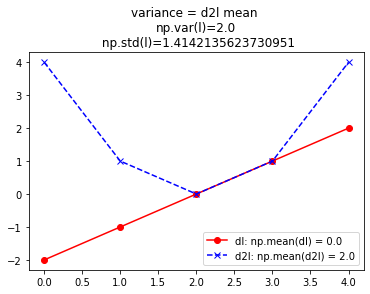

In [136]:
# l = 0,1,2,3
# deviation, squared deviation, variance and std of l

l = np.array((0,1,2,3,4))
ml = np.mean(l)
dl = l-ml
d2l = (l-ml)**2

plt.plot(l, dl, '-or', label = f'dl: {np.mean(dl) = }')
plt.plot(l, d2l, '--xb', label = f'd2l: {np.mean(d2l) = }')
plt.title(f'variance = d2l mean \n{np.var(l)=}\n {np.std(l)=}')
plt.legend()
plt.show()

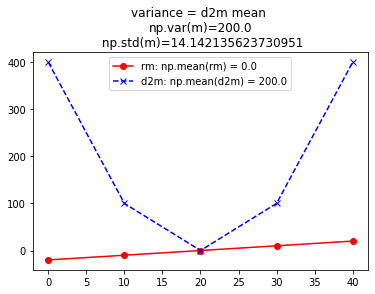

In [137]:
# m = 0,10,20,30,40
# deviation, squared deviation, variance, std of m

m = np.array((0,10,20,30,40))
mm = np.mean(m)
dm = m-mm
d2m = rm**2

plt.plot(m, dm, '-or', label = f'rm: {np.mean(rm) = }')
plt.plot(m, d2m, '--xb', label = f'd2m: {np.mean(d2m) = }')
plt.title(f'variance = d2m mean \n{np.var(m)=}\n {np.std(m)=}')
plt.legend()

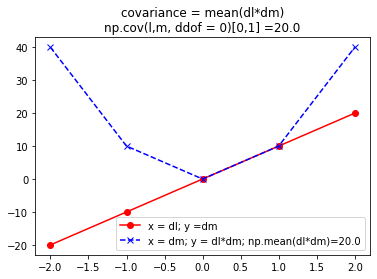

In [138]:
# l = 0,1,2,3,4; m = 0,10,20,30,40
# covariance of l and m

plt.plot(dl,dm, '-or', label = f'x = dl; y =dm')
plt.plot(dl, dl*rm, '--xb', label = f'x = dm; y = dl*dm; {np.mean(dl*dm)=}')
plt.title(f'covariance = mean(dl*dm)\n{np.cov(l,m, ddof = 0)[0,1] =}')
plt.legend()

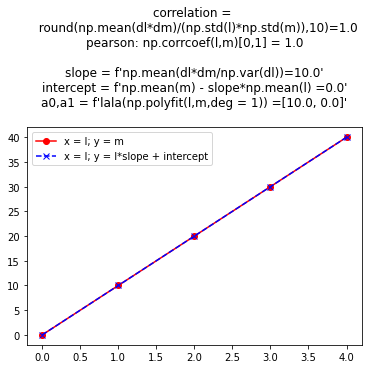

In [139]:
# l = 0,1,2,3,4; m = 0,10,20,30,40
# correlation, slope + intercept of l and m


def lala(x):
    if isinstance(x, float):
        return round(x, 5)
    return [round(y,5) for y in x]

slope = np.mean(dl*dm/np.var(dl))
intercept = np.mean(m) - slope*np.mean(l)

plt.plot(l,m, '-or', label = f'x = l; y = m')
plt.plot(l,l*slope + intercept, '--xb', label = f'x = l; y = l*slope + intercept')

plt.title(f'''correlation = \n  {round(np.mean(dl*dm)/(np.std(l)*np.std(m)),10)=}
pearson: {np.corrcoef(l,m)[0,1] = }

slope = f'{np.mean(dl*dm/np.var(dl))=}'
intercept = f'{np.mean(m) - slope*np.mean(l) =}'
a0,a1 = f'{lala(np.polyfit(l,m,deg = 1)) =}'
''')
plt.legend()
plt.show()

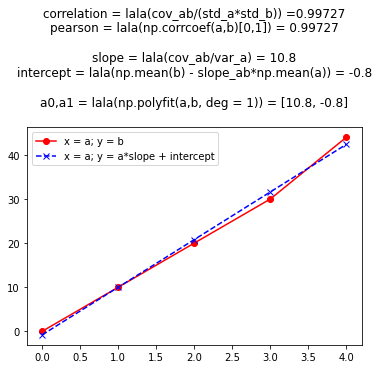

In [140]:
# a = 0,1,2,3,4; b = 0,10,20,30,44
# correlation, slope, intercept

a = np.array((0,1,2,3,4))
b = np.array((0,10,20,30,44))

da = a - np.mean(a)
db = b - np.mean(b)
d2a = da**2
d2b = db**2

var_a = np.mean(d2a)
var_b = np.mean(d2b)

std_a = np.sqrt(var_a)
std_b = np.sqrt(var_b)

cov_ab = np.mean(da*db)

corr_ab = cov_ab/(std_a*std_b)
slope_ab = cov_ab/var_a
intercept_ab = np.mean(b) - slope_ab*np.mean(a)

plt.plot(a,b, '-or', label = 'x = a; y = b')
plt.plot(a,a*slope_ab + intercept_ab, '--xb', label = 'x = a; y = a*slope + intercept')
plt.title(f"""correlation = {lala(cov_ab/(std_a*std_b)) =}
pearson = {lala(np.corrcoef(a,b)[0,1]) = }

slope = {lala(cov_ab/var_a) = }
intercept = {lala(np.mean(b) - slope_ab*np.mean(a)) = }

a0,a1 = {lala(np.polyfit(a,b, deg = 1)) = }
""")
plt.legend()


In [146]:
# residual, RSS
b_model = a*slope_ab + intercept_ab
rb = b_model - b 
r2b = rb**2
rss = np.sum(r2b)
rss
#TODO: find out how to calculate RSS in python

6.4

In [148]:
#  MSE, RMSE
mse = np.mean(r2b)
rmse = np.sqrt(mse)
mse, rmse

(1.28, 1.131370849898476)

In [149]:
# r squared:r2
db = b - np.mean(b)
d2b = db**2

rb = b_model - b
r2b = rb**2

r2 = 1 - (np.sum(r2b)/np.sum(d2b))
r2

0.9945429740791268

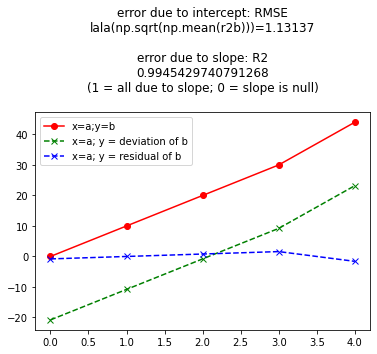

In [172]:
# deviation x residual

plt.plot(a,b, '-or', label = 'x=a;y=b')
plt.plot(a, db, '--xg', label = 'x=a; y = deviation of b')
plt.plot(a, rb, '--xb', label = 'x=a; y = residual of b')
plt.title(f'''error due to intercept: RMSE
{lala(np.sqrt(np.mean(r2b)))=}

error due to slope: R2
{1-(np.sum(r2b)/np.sum(d2b))}
(1 = all due to slope; 0 = slope is null)
''')
plt.legend()
plt.show()

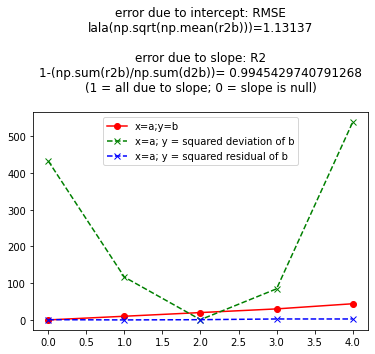

In [175]:
# squared deviation x squared residual
plt.plot(a,b, '-or', label = 'x=a;y=b')
plt.plot(a, d2b, '--xg', label = 'x=a; y = squared deviation of b')
plt.plot(a, r2b, '--xb', label = 'x=a; y = squared residual of b')
plt.title(f'''error due to intercept: RMSE
{lala(np.sqrt(np.mean(r2b)))=}

error due to slope: R2
{1-(np.sum(r2b)/np.sum(d2b))= }
(1 = all due to slope; 0 = slope is null)
''')
plt.legend()
plt.show()